# 밥심 1인 가구 중년·노년층 가상 시나리오 실험

## 요약

이 노트북은 **현재 서비스의 `PersonalUsageModel` 코드**로 1인 가구의 다양한 가상 밥솥 사용 패턴을 시간 순서대로 학습합니다. 합성 미래 기록에서 내부 확인 필요 판정을 고정 24시간 기준과 비교합니다. 선택된 후보 확률 기준은 **0.72**입니다. 보류 가구의 누락 포착률: 개인 모델 **88.5%**, 고정 기준 **100.0%**. 정상일 오경보율: 개인 모델 **7.2%**, 고정 기준 **14.0%**. 훈련 가구에서 선택한 실험 후보는 보류 가구에서 포착률 **95.8%**, 정상일 내부 후보율 8.2%입니다. 가상 가구는 총 **80곳**입니다. 정해 놓은 가상 행동에 대한 내부 판정 결과이며 실제 식사·건강 상태 정확도나 휴대폰 푸시 성능이 아닙니다.


## 방법과 주요 가정

- 50~64세·65세 이상 가상 1인 가구를 8개 생활 유형으로 **균형 있게** 만듭니다. 아침·점심·저녁 사용, 하루 한 번 사용, 이틀 간격 조리, 주말 시간 이동 등을 포함합니다. 연령별 유형 배분과 밥솥 사용 확률은 검증용 가정이며 인구 대표 비율이 아닙니다.
- 각 가구의 28일 기록을 먼저 처리하고 뒤의 28일을 시간 순서대로 평가합니다. 확률 후보는 훈련 가구에서만 선택하고, 다른 가구 시드의 보류 집합과 평소보다 늦게 사용하고 자연스러운 미사용이 늘어나는 변화 집합을 별도로 평가합니다. 미래 개방 시각으로 과거 기준을 만들지 않습니다.
- 정상적인 밥솥 미사용과 의도된 사용 중단을 별도 시나리오로 생성합니다. 라벨은 **생성 시점에** 정하며 모델 점수로 만들지 않습니다. 두 상황이 관측상 같을 수 있어 합성 라벨을 실제 위험의 정답으로 해석할 수 없습니다.
- 실험 후보는 예상 창 뒤에 최대 1시간을 더 관찰하고, 사용 간격의 75백분위를 기준으로 확인 후보를 만듭니다. 이는 보호자 알림을 늦추거나 불필요한 후보를 늘릴 수 있는 절충안입니다. 운영 기본값은 유지하며 후보 선정에도 훈련 가구만 사용합니다.
- 외출·단절은 정답 0으로 채우지 않고 평가에서 제외합니다. 고정 비교는 마지막 개방 이후 24시간 초과입니다. 두 방법 모두 **하루 중 한 번이라도 나온 내부 확인 필요 후보**를 비교하며, 실제 보호자 발송 정책은 별도입니다.
- 가상 집합은 설계한 상황에 편향돼 있습니다. 실제 사용자 기록과 별도 확인 자료가 준비되기 전에는 후보를 운영 알림에 적용하지 않습니다.


## 참고 근거와 사용 범위

- [2025 통계로 보는 1인가구](https://mods.go.kr/board.es?act=view&bid=10820&list_no=442130&mid=a10301010000): 대상 가구의 규모·연령 분포를 설명합니다.
- [국내 중년 1인 가구 식생활 연구](https://www.e-nrp.org/search.php?code=0161NRP&id=10.4162/nrp.2025.19.2.257&vmode=FULL&where=aview): 결식과 식사 빈도의 다양성을 참고합니다.
- [국내 독거 노년층 식생활 연구](https://pmc.ncbi.nlm.nih.gov/articles/PMC7263895/): 독거 노년층의 결식·식단 차이를 참고합니다.
- [2025 양곡소비량조사](https://mods.go.kr/boardDownload.es?bid=230&list_no=443168&seq=12): 연간 쌀 소비량은 한 끼 양이나 밥솥 개방 수로 변환하지 않습니다.
이 문헌들은 밥솥 개방 시각·횟수의 분포를 제공하지 않습니다. 아래 수치는 문헌 추정치가 아니라 명시적인 합성 가정입니다.


## 1. 현재 운영 모델 코드

출처: `domain/personal_model/engine.py` · SHA-256 `54a07aec0be987bcb5a070e78a6a0f635ee9b44bb8c4d028a611d815cde8d873`. 노트북에 코드를 포함해 Colab에서 저장소 연결 없이 실행할 수 있습니다.


In [1]:
"""Learn expected cooker-use windows from observed lid openings.

This is a small probabilistic model, not a meal detector. Weak population
priors initialize four broad usage windows; covered personal days gradually
dominate them. Missing reports and declared absence never become inactivity.
"""


from datetime import date, datetime, time, timedelta, timezone
from math import atan2, ceil, cos, pi, sin
from typing import Mapping


KST = timezone(timedelta(hours=9))
DAY_MINUTES = 24 * 60
PRIORS = (
    ("slot_1", 8 * 60, 0.35),
    ("slot_2", 13 * 60, 0.45),
    ("slot_3", 19 * 60, 0.40),
    ("slot_4", 30, 0.10),
)
USAGE_GROUP = timedelta(minutes=60)


def _time(value: str) -> datetime:
    parsed = datetime.fromisoformat(value.replace("Z", "+00:00"))
    if parsed.tzinfo is None or parsed.utcoffset() is None:
        raise ValueError("model timestamps require timezone")
    return parsed.astimezone(timezone.utc)


def _minutes(moment: datetime) -> float:
    local = moment.astimezone(KST)
    return local.hour * 60 + local.minute + local.second / 60


def _distance(a: float, b: float) -> float:
    return abs((a - b + DAY_MINUTES / 2) % DAY_MINUTES - DAY_MINUTES / 2)


def _circular_mean(values: list[float], prior: float) -> float:
    angles = [2 * pi * item / DAY_MINUTES for item in [prior, *values]]
    x = sum(cos(angle) for angle in angles)
    y = sum(sin(angle) for angle in angles)
    return atan2(y, x) * DAY_MINUTES / (2 * pi) % DAY_MINUTES


class PersonalUsageModel:
    def __init__(self, *, min_covered_days: int = 7, history_days: int = 28,
                 window_hours: float = 2.0, alert_probability: float = 0.72,
                 late_grace_hours: float = 0.0, interval_quantile: float = 0.95) -> None:
        if min_covered_days < 1 or history_days < min_covered_days:
            raise ValueError("invalid learning window")
        if (not 0 < window_hours <= 3 or not 0 < alert_probability <= 1 or
                not 0 <= late_grace_hours <= 2 or not 0.5 <= interval_quantile <= 0.95):
            raise ValueError("invalid model window or alert probability")
        self.min_covered_days = min_covered_days
        self.history_days = history_days
        self.window = timedelta(hours=window_hours)
        self.alert_probability = alert_probability
        self.late_grace = timedelta(hours=late_grace_hours)
        self.interval_quantile = interval_quantile
        self._devices: dict[tuple[str, str], dict[str, object]] = {}
        self._away_intervals: list[tuple[datetime, datetime]] = []
        self._away_since: datetime | None = None

    @property
    def device_keys(self) -> tuple[tuple[str, str], ...]:
        return tuple(self._devices)

    def _device(self, source: str, device_id: str) -> dict[str, object]:
        return self._devices.setdefault((source, device_id), {
            "opens": [], "raw_opens": [], "coverage": [], "online_since": None,
            "last_seen": None, "evaluations": {}, "trend_evaluations": {},
            "decline_streak": 0, "recovery_streak": 0, "trend_active": False,
        })

    def dump_state(self) -> dict[str, object]:
        devices = []
        for (source, device_id), state in self._devices.items():
            devices.append({
                "source": source, "device_id": device_id,
                "opens": [at.isoformat() for at in state["opens"]],
                "raw_opens": [at.isoformat() for at in state["raw_opens"]],
                "coverage": [[start.isoformat(), end.isoformat()] for start, end in state["coverage"]],
                "online_since": state["online_since"].isoformat() if state["online_since"] else None,
                "last_seen": state["last_seen"].isoformat() if state["last_seen"] else None,
                "evaluations": dict(state["evaluations"]),
                "trend_evaluations": dict(state["trend_evaluations"]),
                "decline_streak": state["decline_streak"],
                "recovery_streak": state["recovery_streak"],
                "trend_active": state["trend_active"],
            })
        return {
            "devices": devices,
            "away_intervals": [[start.isoformat(), end.isoformat()] for start, end in self._away_intervals],
            "away_since": self._away_since.isoformat() if self._away_since else None,
        }

    def load_state(self, stored: Mapping[str, object]) -> None:
        self._devices.clear()
        for item in stored.get("devices", []):
            source, device_id = item["source"], item["device_id"]
            state = self._device(source, device_id)
            # Older snapshots only stored group starts. Treat those as the
            # available observations without inventing the missing raw opens.
            state["raw_opens"] = sorted(_time(at) for at in item.get("raw_opens", item.get("opens", [])))
            state["opens"] = self._group_opens(state["raw_opens"])
            state["coverage"] = [(_time(start), _time(end)) for start, end in item.get("coverage", [])]
            state["evaluations"] = dict(item.get("evaluations", {}))
            state["trend_evaluations"] = dict(item.get("trend_evaluations", {}))
            state["decline_streak"] = int(item.get("decline_streak", 0))
            state["recovery_streak"] = int(item.get("recovery_streak", 0))
            state["trend_active"] = bool(item.get("trend_active", False))
            # A process restart interrupts observed coverage. Close it at the
            # last actual heartbeat; never span an unobserved downtime.
            start = item.get("online_since")
            end = item.get("last_seen")
            if start and end and _time(end) > _time(start):
                state["coverage"].append((_time(start), _time(end)))
            state["online_since"] = None
            state["last_seen"] = _time(end) if end else None
        self._away_intervals = [(_time(start), _time(end)) for start, end in stored.get("away_intervals", [])]
        self._away_since = None
        if stored.get("away_since"):
            # The persisted away flag is reapplied by the host after setup.
            self._away_since = _time(stored["away_since"])

    def set_away(self, away: bool, at: str) -> None:
        moment = _time(at)
        if away and self._away_since is None:
            self._away_since = moment
        elif not away and self._away_since is not None:
            if moment > self._away_since:
                self._away_intervals.append((self._away_since, moment))
            self._away_since = None

    def availability(self, source: str, device_id: str, online: bool, at: str) -> None:
        moment = _time(at)
        state = self._device(source, device_id)
        last = state["last_seen"]
        if last is not None and moment < last:
            return
        state["last_seen"] = moment
        start = state["online_since"]
        if online:
            if start is None:
                state["online_since"] = moment
        elif start is not None:
            if moment > start:
                state["coverage"].append((start, moment))
            state["online_since"] = None
        self._prune(state, moment)

    def observe(self, event: Mapping[str, object]) -> None:
        kind = event.get("event_type")
        if kind not in {"device_online", "device_offline", "lid_opened"}:
            return
        source, device_id, at = event.get("source"), event.get("device_id"), event.get("observed_at")
        if not all(isinstance(item, str) and item for item in (source, device_id, at)):
            raise ValueError("canonical event needs source, device_id and observed_at")
        moment = _time(at)
        if kind in {"device_online", "device_offline"}:
            self.availability(source, device_id, kind == "device_online", at)
            return
        if event.get("availability") != "online":
            return
        state = self._device(source, device_id)
        raw_opens = state["raw_opens"]
        if moment not in raw_opens:
            raw_opens.append(moment)
            raw_opens.sort()
            state["opens"] = self._group_opens(raw_opens)
        self._prune(state, moment)

    @staticmethod
    def _group_opens(raw_opens: list[datetime]) -> list[datetime]:
        starts: list[datetime] = []
        for moment in raw_opens:
            if not starts or moment >= starts[-1] + USAGE_GROUP:
                starts.append(moment)
        return starts

    def _prune(self, state: dict[str, object], now: datetime) -> None:
        cutoff = now - timedelta(days=self.history_days + 3)
        state["raw_opens"] = [at for at in state["raw_opens"] if at >= cutoff]
        state["opens"] = self._group_opens(state["raw_opens"])
        state["coverage"] = [(start, end) for start, end in state["coverage"] if end >= cutoff]
        state["evaluations"] = {
            key: status for key, status in state["evaluations"].items()
            if date.fromisoformat(key.split("|", 1)[0]) >= cutoff.astimezone(KST).date()
        }
        state["trend_evaluations"] = {
            key: value for key, value in state["trend_evaluations"].items()
            if date.fromisoformat(key) >= cutoff.astimezone(KST).date()
        }
        self._away_intervals = [(start, end) for start, end in self._away_intervals if end >= cutoff]

    def _centers(self, state: dict[str, object], before: date) -> list[float]:
        cutoff = before - timedelta(days=self.history_days)
        samples = [
            _minutes(at) for at in state["opens"]
            if cutoff <= at.astimezone(KST).date() < before
            and not self._away_at(at)
        ]
        centers = [float(prior) for _, prior, _ in PRIORS]
        for _ in range(4):
            groups = [[] for _ in PRIORS]
            for item in samples:
                closest = min(range(len(centers)), key=lambda index: _distance(item, centers[index]))
                if _distance(item, centers[closest]) <= 6 * 60:
                    groups[closest].append(item)
            centers = [
                _circular_mean(group, float(PRIORS[index][1])) if group else float(PRIORS[index][1])
                for index, group in enumerate(groups)
            ]
        return centers

    def _away_at(self, moment: datetime) -> bool:
        return any(start <= moment < end for start, end in self._away_intervals) or (
            self._away_since is not None and moment >= self._away_since
        )

    def _window(self, day: date, center: float) -> tuple[datetime, datetime]:
        local_midnight = datetime.combine(day, time.min, KST)
        middle = local_midnight + timedelta(minutes=center)
        return (middle - self.window).astimezone(timezone.utc), (middle + self.window).astimezone(timezone.utc)

    def _covered(self, state: dict[str, object], start: datetime, end: datetime, now: datetime) -> bool:
        intervals = list(state["coverage"])
        if state["online_since"] is not None:
            intervals.append((state["online_since"], now))
        cursor = start
        for left, right in sorted(intervals):
            if right <= cursor:
                continue
            if left > cursor:
                return False
            cursor = max(cursor, right)
            if cursor >= end:
                return True
        return False

    def _away_window(self, start: datetime, end: datetime) -> bool:
        intervals = self._away_intervals[:]
        if self._away_since is not None:
            intervals.append((self._away_since, end))
        return any(left < end and right > start for left, right in intervals)

    def _used(self, state: dict[str, object], start: datetime, end: datetime) -> bool:
        return any(start <= at < end for at in state["opens"])

    def _profile(self, state: dict[str, object], day: date, slot: int, center: float,
                 now: datetime) -> dict[str, object]:
        count = positive = group_count = group_positive = weekday_count = weekday_positive = 0.0
        covered_days = 0
        for offset in range(1, self.history_days + 1):
            previous = day - timedelta(days=offset)
            start, end = self._window(previous, center)
            if not self._covered(state, start, end, now) or self._away_window(start, end):
                continue
            covered_days += 1
            flagged = state["evaluations"].get(f"{previous.isoformat()}|{slot}") == "check_required"
            weight = 0.15 if flagged else 1.0
            used = self._used(state, start, end)
            count += weight
            positive += weight * used
            if (previous.weekday() >= 5) == (day.weekday() >= 5):
                group_count += weight
                group_positive += weight * used
            if previous.weekday() == day.weekday():
                weekday_count += weight
                weekday_positive += weight * used
        prior_probability = PRIORS[slot][2]
        all_probability = (2 * prior_probability + positive) / (2 + count)
        group_probability = (4 * all_probability + group_positive) / (4 + group_count)
        probability = (3 * group_probability + weekday_positive) / (3 + weekday_count)
        return {
            "slot": PRIORS[slot][0], "expected_time": (
                datetime.combine(day, time.min, KST) + timedelta(minutes=center)
            ).isoformat(),
            "probability": round(probability, 4),
            "covered_days": covered_days,
            "personal_weight": round(count / (2 + count), 4),
        }

    def evaluate(self, source: str, device_id: str, as_of: str, *, online: bool,
                 away: bool = False) -> list[dict[str, object]]:
        now = _time(as_of)
        state = self._device(source, device_id)
        self.availability(source, device_id, online, as_of)
        local_day = now.astimezone(KST).date()
        decisions = []
        for day in (local_day - timedelta(days=1), local_day):
            centers = self._centers(state, day)
            for index, center in enumerate(centers):
                start, end = self._window(day, center)
                decision_at = end + self.late_grace
                if not decision_at <= now < decision_at + timedelta(hours=1):
                    continue
                evaluation_key = f"{day.isoformat()}|{index}"
                if evaluation_key in state["evaluations"]:
                    continue
                profile = self._profile(state, day, index, center, now)
                if away or self._away_window(start, decision_at):
                    status, reason, score = "away", "AWAY_DECLARED", None
                elif not self._covered(state, start, decision_at, now):
                    status, reason, score = "data_unavailable", "COOKER_DATA_UNAVAILABLE", None
                elif profile["covered_days"] < self.min_covered_days:
                    status, reason, score = "learning", "PATTERN_LEARNING", None
                elif self._used(state, start, decision_at):
                    status, reason, score = "normal", None, round(1 - profile["probability"], 4)
                elif profile["probability"] >= self.alert_probability:
                    status, reason, score = "check_required", "EXPECTED_USE_MISSING", profile["probability"]
                else:
                    status, reason, score = "no_expectation", None, profile["probability"]
                state["evaluations"][evaluation_key] = status
                decisions.append({
                    "source": source, "device_id": device_id, "as_of": decision_at.isoformat(),
                    "routine_status": status,
                    "severity": "warning" if status == "check_required" else "info" if reason else "none",
                    "reason_codes": [reason] if reason else [], "score": score,
                    "evidence": {
                        **profile, "observed_use": self._used(state, start, decision_at),
                        "window_start": start.isoformat(), "window_end": end.isoformat(),
                        "decision_at": decision_at.isoformat(),
                        "model": "personal_usage_v1",
                    },
                })
        self._prune(state, now)
        return sorted(decisions, key=lambda item: item["as_of"])

    def profile(self, source: str, device_id: str, as_of: str) -> dict[str, object]:
        now = _time(as_of)
        state = self._device(source, device_id)
        day = now.astimezone(KST).date()
        centers = self._centers(state, day)
        windows = [self._profile(state, day, index, center, now) for index, center in enumerate(centers)]
        recent_opens = [at for at in state["opens"] if now - timedelta(hours=24) < at <= now]
        previous_opens = [at for at in state["opens"] if at <= now]
        return {
            "source": source, "device_id": device_id, "as_of": as_of,
            "model": "personal_usage_v1", "min_covered_days": self.min_covered_days,
            "windows": windows,
            "lid_open_count_24h": len(recent_opens),
            "last_lid_open_at": previous_opens[-1].isoformat() if previous_opens else None,
            "ready": any(window["covered_days"] >= self.min_covered_days for window in windows),
        }

    def evaluate_interval(self, source: str, device_id: str, as_of: str, *, online: bool,
                          away: bool = False) -> dict[str, object] | None:
        """Use covered inter-use intervals when no clock-time window is reliable."""
        now = _time(as_of)
        state = self._device(source, device_id)
        if not online or away or not state["opens"]:
            return None
        profile = self.profile(source, device_id, as_of)
        if any(window["probability"] >= self.alert_probability and
               window["covered_days"] >= self.min_covered_days for window in profile["windows"]):
            return None
        opens = [at for at in state["opens"] if at <= now and not self._away_at(at)]
        intervals = [right - left for left, right in zip(opens, opens[1:])
                     if self._covered(state, left, right, now) and not self._away_window(left, right)]
        if len(intervals) < self.min_covered_days:
            return None
        intervals.sort()
        p95 = intervals[ceil(0.95 * len(intervals)) - 1]
        limit = intervals[ceil(self.interval_quantile * len(intervals)) - 1]
        last = opens[-1]
        if not self._covered(state, last, now, now) or self._away_window(last, now):
            return None
        elapsed = now - last
        status = "normal" if elapsed <= limit else "watch" if elapsed <= limit + timedelta(hours=2) else "check_required"
        return {
            "source": source, "device_id": device_id, "as_of": as_of,
            "routine_status": status,
            "severity": "warning" if status == "check_required" else "none",
            "reason_codes": ["UNUSUAL_USE_GAP"] if status == "check_required" else [],
            "score": None,
            "evidence": {"model": "personal_interval_v1", "sample_count": len(intervals),
                         "last_use_at": last.isoformat(), "p95_hours": round(p95.total_seconds() / 3600, 2),
                         "threshold_hours": round(limit.total_seconds() / 3600, 2),
                         "interval_quantile": self.interval_quantile,
                         "elapsed_hours": round(elapsed.total_seconds() / 3600, 2)},
        }

    def evaluate_trend(self, source: str, device_id: str, as_of: str, *, online: bool,
                       away: bool = False) -> dict[str, object] | None:
        """Evaluate complete covered days; never treat an outage as zero use."""
        now = _time(as_of)
        state = self._device(source, device_id)
        day = now.astimezone(KST).date() - timedelta(days=1)
        key = day.isoformat()
        if key in state["trend_evaluations"]:
            return None
        state["trend_evaluations"][key] = "insufficient"
        if not online or away:
            return None
        counts: list[tuple[date, int]] = []
        for offset in range(28, 0, -1):
            sample_day = now.astimezone(KST).date() - timedelta(days=offset)
            start = datetime.combine(sample_day, time.min, KST).astimezone(timezone.utc)
            end = start + timedelta(days=1)
            if not self._covered(state, start, end, now) or self._away_window(start, end):
                continue
            counts.append((sample_day, sum(start <= opening < end for opening in state["opens"])))
        recent = [count for sample_day, count in counts if day - timedelta(days=6) <= sample_day <= day]
        reference = [count for sample_day, count in counts if day - timedelta(days=27) <= sample_day < day - timedelta(days=6)]
        if len(recent) < 5 or len(reference) < 10:
            return None
        recent_rate = sum(recent) / len(recent)
        reference_rate = sum(reference) / len(reference)
        decline = reference_rate > 0 and recent_rate <= reference_rate * 0.7
        state["trend_evaluations"][key] = "declining" if decline else "normal"
        state["decline_streak"] = state["decline_streak"] + 1 if decline else 0
        state["recovery_streak"] = 0 if decline else state["recovery_streak"] + 1
        if decline and state["decline_streak"] >= 3 and not state["trend_active"]:
            state["trend_active"] = True
            status, reason = "check_required", "DECLINING_USAGE"
        elif not decline and state["recovery_streak"] >= 3 and state["trend_active"]:
            state["trend_active"] = False
            status, reason = "normal", "DECLINE_RESOLVED"
        else:
            return None
        return {
            "source": source, "device_id": device_id, "as_of": now.isoformat(),
            "routine_status": status, "severity": "warning" if decline else "none",
            "reason_codes": [reason],
            "score": round(1 - recent_rate / reference_rate, 4) if reference_rate else None,
            "evidence": {"model": "personal_usage_v1", "assessment_type": "declining_usage",
                         "recent_days": len(recent), "reference_days": len(reference),
                         "recent_rate": round(recent_rate, 4), "reference_rate": round(reference_rate, 4)},
        }


## 2. 가상 가구 생성과 날짜 순서 평가

출처: `ai/target_cohort_experiment.py` · SHA-256 `ced551ac8c5b071c0f4add97aa9c59dd066e5c1719600ba2f895f52a6bb60d2d`. 가상 라벨과 판정 코드는 분리돼 있습니다.


In [2]:
"""Deterministic stress test for single-person cooker-use routines.

Profiles are deliberately balanced test cases, not estimates of Korean
population prevalence. Scripted interruptions are not meal or health labels.
"""


from datetime import datetime, timedelta, timezone
from random import Random



KST = timezone(timedelta(hours=9))
START = datetime(2026, 1, 5, tzinfo=KST)
HISTORY_DAYS = 28
FUTURE_DAYS = 28
TOTAL_DAYS = HISTORY_DAYS + FUTURE_DAYS
TRAIN_SEEDS = (101, 103, 107, 109)
HOLDOUT_SEEDS = (301, 307, 311, 313)
STRESS_SEEDS = (501, 503)
THRESHOLDS = (0.72, 0.84, 0.90)
VARIANTS = {
    "current": (0.0, 0.95),
    "late_grace": (1.0, 0.95),
    "grace_and_cadence": (1.0, 0.75),
}

# These timings and probabilities are stress-test assumptions. The cited
# population studies motivate diversity, not these exact cooker-use rates.
PROFILES = {
    "early_single": {"age": "65_plus", "hours": (7,), "skip": 0.07, "jitter": 25},
    "midday_single": {"age": "65_plus", "hours": (12,), "skip": 0.10, "jitter": 30},
    "evening_single": {"age": "50_64", "hours": (19,), "skip": 0.10, "jitter": 30},
    "breakfast_dinner": {"age": "65_plus", "hours": (8, 18), "skip": 0.08, "jitter": 25},
    "lunch_dinner": {"age": "50_64", "hours": (13, 19), "skip": 0.13, "jitter": 35},
    "three_windows": {"age": "65_plus", "hours": (8, 13, 19), "skip": 0.07, "jitter": 25},
    "batch_every_other_day": {"age": "65_plus", "hours": (17,), "skip": 0.07, "jitter": 40},
    "variable_weekend": {"age": "50_64", "hours": (19,), "skip": 0.14, "jitter": 55},
}


def _at(day: int, hour: float = 0) -> datetime:
    return START + timedelta(days=day, hours=hour)


def _event(device_id: str, kind: str, moment: datetime) -> dict[str, str]:
    return {"source": "simulator", "device_id": device_id,
            "event_type": kind, "observed_at": moment.isoformat(),
            "availability": "offline" if kind == "device_offline" else "online"}


def _planned(profile: str, day: int) -> bool:
    return profile != "batch_every_other_day" or day % 2 == 0


def _interruptions(profile: str, seed: int) -> set[int]:
    eligible = [day for day in range(HISTORY_DAYS, TOTAL_DAYS) if _planned(profile, day)]
    offset = seed % 2
    return {eligible[index + offset] for index in (len(eligible) // 4, len(eligible) // 2,
                                                   3 * len(eligible) // 4)}


def run_household(seed: int, profile: str, threshold: float,
                  *, stress: bool = False, late_grace_hours: float = 0.0,
                  interval_quantile: float = 0.95) -> list[dict[str, object]]:
    """Replay one home chronologically; labels are set before model scoring."""
    if profile not in PROFILES:
        raise ValueError("unknown synthetic profile")
    spec = PROFILES[profile]
    rng = Random(seed * 1009 + list(PROFILES).index(profile))
    device_id = f"synthetic_{profile}_{seed}"
    model = PersonalUsageModel(alert_probability=threshold,
                               late_grace_hours=late_grace_hours,
                               interval_quantile=interval_quantile)
    gap_days = _interruptions(profile, seed)
    away_days = {HISTORY_DAYS + 5 + seed % 2}
    outage_days = {HISTORY_DAYS + 12 + seed % 2}
    rows: list[dict[str, object]] = []
    last_open: datetime | None = None

    for day in range(TOTAL_DAYS):
        baseline = _at(day)
        away = day in away_days
        online = day not in outage_days
        planned = _planned(profile, day)
        interruption = day in gap_days and not away and online
        # Stress homes have later usage and more legitimate non-use after the
        # historical period. Neither change is shown to the model in advance.
        skip_probability = float(spec["skip"]) + (0.18 if stress and day >= HISTORY_DAYS else 0)
        natural_skip = planned and not interruption and rng.random() < skip_probability
        scenario = ("away" if away else "offline" if not online else
                    "scripted_interruption" if interruption else
                    "ordinary_nonuse" if natural_skip or not planned else
                    "routine_shift" if stress and day >= HISTORY_DAYS else "routine")

        model.set_away(away, baseline.isoformat())
        model.observe(_event(device_id, "device_online" if online else "device_offline", baseline))
        planned_actions: list[tuple[datetime, str]] = []
        if online and not away and planned and not (interruption or natural_skip):
            for hour in spec["hours"]:
                shift = 1.5 if stress and day >= HISTORY_DAYS else 0
                if profile == "variable_weekend" and baseline.weekday() >= 5:
                    shift += 1.5
                jitter = max(-100, min(100, rng.gauss(0, int(spec["jitter"]))))
                opening = _at(day, int(hour)) + timedelta(hours=shift, minutes=jitter)
                planned_actions.append((opening, "open"))
                if rng.random() < 0.22:
                    planned_actions.append((opening + timedelta(minutes=9), "repeat"))

        # Model window centers are computed from prior days only. Evaluate
        # each one shortly after its end, as a periodic worker would.
        centers = model.profile("simulator", device_id, baseline.isoformat())["windows"]
        checks = [datetime.fromisoformat(item["expected_time"]) + timedelta(hours=2.5 + late_grace_hours)
                  for item in centers]
        actions = [(moment, kind) for moment, kind in planned_actions]
        actions += [(moment, "evaluate") for moment in checks]
        flagged = False
        for moment, action in sorted(actions):
            if action in {"open", "repeat"}:
                model.observe(_event(device_id, "lid_opened", moment))
                last_open = moment
            else:
                decisions = model.evaluate("simulator", device_id, moment.isoformat(),
                                           online=online, away=away)
                flagged |= any(item["routine_status"] == "check_required" for item in decisions)
        end = _at(day, 23 + 59 / 60)
        if online:
            model.availability("simulator", device_id, True, end.isoformat())
        interval = model.evaluate_interval("simulator", device_id, end.isoformat(),
                                           online=online, away=away)
        flagged |= bool(interval and interval["routine_status"] == "check_required")
        rows.append({
            "household": device_id, "profile": profile, "age_group": spec["age"],
            "day": day, "split": "history" if day < HISTORY_DAYS else "future",
            "scenario": scenario, "label": (None if day < HISTORY_DAYS or away or not online
                                            else int(interruption)),
            "personal_alert": int(flagged),
            "fixed_24h_alert": int(online and not away and last_open is not None and
                                   end - last_open > timedelta(hours=24)),
        })
    return rows


def cohort(seeds: tuple[int, ...], threshold: float,
           *, stress: bool = False, late_grace_hours: float = 0.0,
           interval_quantile: float = 0.95) -> list[dict[str, object]]:
    return [row for seed in seeds for profile in PROFILES
            for row in run_household(seed, profile, threshold, stress=stress,
                                     late_grace_hours=late_grace_hours,
                                     interval_quantile=interval_quantile)]


def score(rows: list[dict[str, object]], field: str) -> dict[str, int | float]:
    future = [row for row in rows if row["split"] == "future"]
    eligible = [row for row in future if row["label"] is not None]
    tp = sum(row["label"] == 1 and row[field] == 1 for row in eligible)
    fp = sum(row["label"] == 0 and row[field] == 1 for row in eligible)
    fn = sum(row["label"] == 1 and row[field] == 0 for row in eligible)
    tn = sum(row["label"] == 0 and row[field] == 0 for row in eligible)
    return {"households": len({row["household"] for row in future}),
            "eligible_days": len(eligible), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "recall": round(tp / (tp + fn), 4) if tp + fn else 0.0,
            "false_positive_rate": round(fp / (fp + tn), 4) if fp + tn else 0.0,
            "false_alerts_per_household_28d": round(fp / len({row["household"] for row in future}), 3),
            "abstained_days": len(future) - len(eligible),
            "alerted_away_or_offline": sum(row["label"] is None and row[field] == 1 for row in future)}


def _by(rows: list[dict[str, object]], key: str) -> dict[str, dict[str, int | float]]:
    return {str(value): score([row for row in rows if row[key] == value], "personal_alert")
            for value in sorted({row[key] for row in rows if row["split"] == "future"})}


def experiment() -> dict[str, object]:
    training = []
    for threshold in THRESHOLDS:
        training.append({"threshold": threshold,
                         **score(cohort(TRAIN_SEEDS, threshold), "personal_alert")})
    # Choose on training homes only; favor fewer nuisance alerts for a
    # caregiver-facing workflow. This objective is an experiment assumption.
    selected = max(training, key=lambda item: (
        float(item["recall"]) - 2 * float(item["false_positive_rate"]),
        -abs(float(item["threshold"]) - 0.72)))["threshold"]
    variant_training = []
    for name, (grace, quantile) in VARIANTS.items():
        variant_training.append({"name": name, "late_grace_hours": grace,
                                 "interval_quantile": quantile,
                                 **score(cohort(TRAIN_SEEDS, float(selected),
                                                late_grace_hours=grace,
                                                interval_quantile=quantile), "personal_alert")})
    # All settings are chosen without examining holdout or stress homes.
    candidate_name = max(variant_training, key=lambda item: (
        float(item["recall"]) - 2 * float(item["false_positive_rate"]),
        -float(item["late_grace_hours"])))["name"]
    candidate_grace, candidate_quantile = VARIANTS[str(candidate_name)]
    holdout = cohort(HOLDOUT_SEEDS, float(selected))
    stress = cohort(STRESS_SEEDS, float(selected), stress=True)
    candidate_holdout = cohort(HOLDOUT_SEEDS, float(selected),
                               late_grace_hours=candidate_grace,
                               interval_quantile=candidate_quantile)
    candidate_stress = cohort(STRESS_SEEDS, float(selected), stress=True,
                              late_grace_hours=candidate_grace,
                              interval_quantile=candidate_quantile)
    return {
        "scope": "Balanced synthetic single-person cooker-use stress test; no meal or health labels.",
        "model": "PersonalUsageModel from domain/personal_model/engine.py",
        "profile_count": len(PROFILES), "profile_names": list(PROFILES),
        "train_seeds": list(TRAIN_SEEDS), "holdout_seeds": list(HOLDOUT_SEEDS),
        "stress_seeds": list(STRESS_SEEDS),
        "history_days_per_household": HISTORY_DAYS, "future_days_per_household": FUTURE_DAYS,
        "training_candidates": training, "selected_threshold": selected,
        "variant_training": variant_training, "selected_variant": candidate_name,
        "selected_variant_settings": {"late_grace_hours": candidate_grace,
                                      "interval_quantile": candidate_quantile},
        "holdout_personal": score(holdout, "personal_alert"),
        "holdout_fixed_24h": score(holdout, "fixed_24h_alert"),
        "holdout_by_profile": _by(holdout, "profile"),
        "holdout_by_age_group": _by(holdout, "age_group"),
        "holdout_by_scenario": _by(holdout, "scenario"),
        "candidate_holdout": score(candidate_holdout, "personal_alert"),
        "candidate_by_profile": _by(candidate_holdout, "profile"),
        "stress_personal": score(stress, "personal_alert"),
        "stress_fixed_24h": score(stress, "fixed_24h_alert"),
        "stress_by_profile": _by(stress, "profile"),
        "candidate_stress": score(candidate_stress, "personal_alert"),
        "example_future_rows": [row for row in holdout if row["household"] ==
                                f"synthetic_lunch_dinner_{HOLDOUT_SEEDS[0]}" and
                                row["split"] == "future"][:10],
    }


## 3. 후보 선택과 보류 가구 결과

`TP/FP/FN/TN`은 외출·단절을 제외한 가구·날 단위입니다. 후보 선택에는 보류 가구 결과를 사용하지 않습니다.


In [3]:
result = experiment()
print("가상 생활 유형:", result["profile_count"], "| 훈련 가구:", len(result["train_seeds"]) * result["profile_count"],
      "| 보류 가구:", len(result["holdout_seeds"]) * result["profile_count"],
      "| 변화 시나리오 가구:", len(result["stress_seeds"]) * result["profile_count"])
print("후보 기준값 (훈련 사용자에서만 선택):", result["selected_threshold"])
print("보류 사용자 개인 모델:", result["holdout_personal"])
print("보류 사용자 고정 24시간 기준:", result["holdout_fixed_24h"])
print("생활 변화 시나리오 개인 모델:", result["stress_personal"])
print("훈련 가구에서 선택한 실험 후보:", result["selected_variant"], result["selected_variant_settings"])
print("실험 후보 보류 가구:", result["candidate_holdout"])
print("실험 후보 생활 변화 가구:", result["candidate_stress"])
print("유형별 보류 결과:")
for name, values in result["holdout_by_profile"].items():
    proposed = result["candidate_by_profile"][name]
    print(name, "현재/후보 포착률", f'{values["recall"]:.1%}', f'{proposed["recall"]:.1%}',
          "현재/후보 28일당 불필요한 후보", values["false_alerts_per_household_28d"],
          proposed["false_alerts_per_household_28d"])


가상 생활 유형: 8 | 훈련 가구: 32 | 보류 가구: 32 | 변화 시나리오 가구: 16
후보 기준값 (훈련 사용자에서만 선택): 0.72
보류 사용자 개인 모델: {'households': 32, 'eligible_days': 832, 'tp': 85, 'fp': 53, 'fn': 11, 'tn': 683, 'recall': 0.8854, 'false_positive_rate': 0.072, 'false_alerts_per_household_28d': 1.656, 'abstained_days': 64, 'alerted_away_or_offline': 0}
보류 사용자 고정 24시간 기준: {'households': 32, 'eligible_days': 832, 'tp': 96, 'fp': 103, 'fn': 0, 'tn': 633, 'recall': 1.0, 'false_positive_rate': 0.1399, 'false_alerts_per_household_28d': 3.219, 'abstained_days': 64, 'alerted_away_or_offline': 0}
생활 변화 시나리오 개인 모델: {'households': 16, 'eligible_days': 416, 'tp': 43, 'fp': 103, 'fn': 5, 'tn': 265, 'recall': 0.8958, 'false_positive_rate': 0.2799, 'false_alerts_per_household_28d': 6.438, 'abstained_days': 32, 'alerted_away_or_offline': 0}
훈련 가구에서 선택한 실험 후보: grace_and_cadence {'late_grace_hours': 1.0, 'interval_quantile': 0.75}
실험 후보 보류 가구: {'households': 32, 'eligible_days': 832, 'tp': 92, 'fp': 60, 'fn': 4, 'tn': 676, 'recall': 0.9583

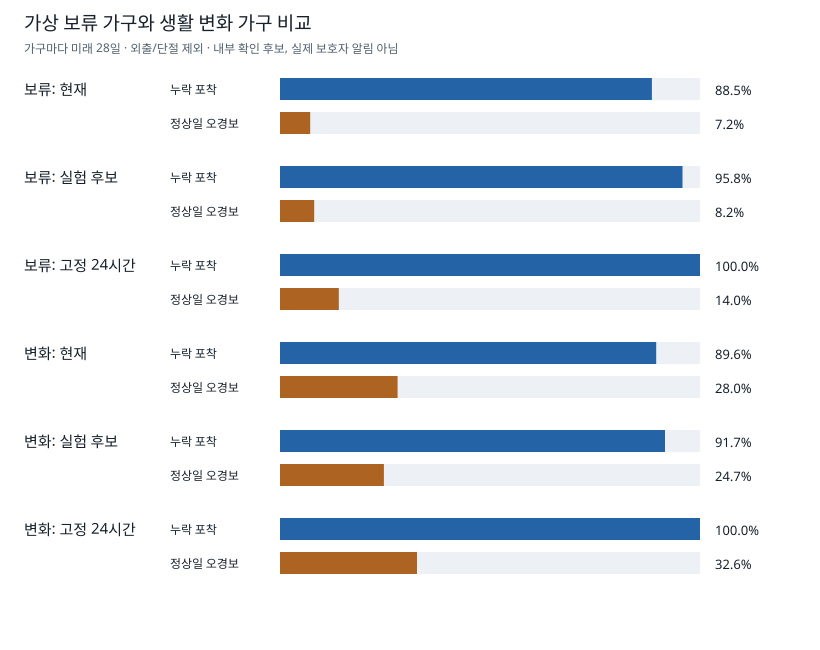

In [4]:
from html import escape
from IPython.display import SVG, display

def comparison_svg(result):
    personal = result["holdout_personal"]
    fixed = result["holdout_fixed_24h"]
    measures = [("보류: 현재", personal), ("보류: 실험 후보", result["candidate_holdout"]),
                ("보류: 고정 24시간", fixed), ("변화: 현재", result["stress_personal"]),
                ("변화: 실험 후보", result["candidate_stress"]),
                ("변화: 고정 24시간", result["stress_fixed_24h"])]
    parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="820" height="650" viewBox="0 0 820 650">',
             '<rect width="820" height="650" fill="white"/>',
             '<text x="24" y="30" font-family="sans-serif" font-size="19" fill="#17212b">가상 보류 가구와 생활 변화 가구 비교</text>',
             '<text x="24" y="53" font-family="sans-serif" font-size="12" fill="#52606d">가구마다 미래 28일 · 외출/단절 제외 · 내부 확인 후보, 실제 보호자 알림 아님</text>']
    for index, (name, values) in enumerate(measures):
        y = 78 + index * 88
        parts.append(f'<text x="24" y="{y+17}" font-family="sans-serif" font-size="15" fill="#17212b">{escape(name)}</text>')
        for metric, offset, color, label in (("recall", 0, "#2463a6", "누락 포착"),
                                             ("false_positive_rate", 34, "#ad6321", "정상일 오경보")):
            value = values[metric]
            parts.extend([f'<text x="170" y="{y+offset+16}" font-family="sans-serif" font-size="12" fill="#17212b">{label}</text>',
                          f'<rect x="280" y="{y+offset}" width="420" height="22" fill="#edf1f5"/>',
                          f'<rect x="280" y="{y+offset}" width="{420*value:.1f}" height="22" fill="{color}"/>',
                          f'<text x="715" y="{y+offset+17}" font-family="sans-serif" font-size="13" fill="#17212b">{value*100:.1f}%</text>'])
    parts.append('</svg>')
    return ''.join(parts)

display(SVG(comparison_svg(result)))


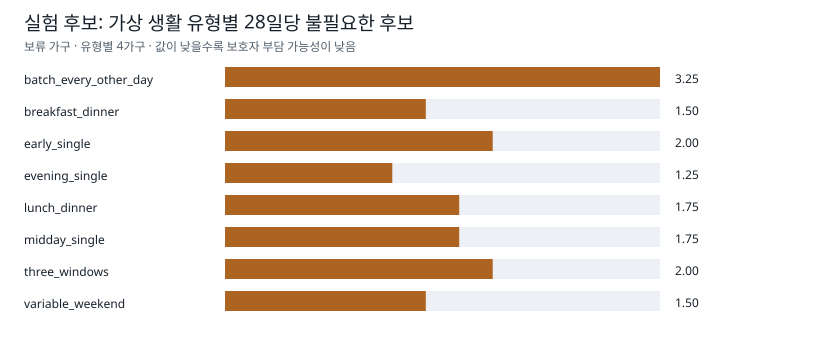

In [5]:
from html import escape
from IPython.display import SVG, display

def profile_svg(result):
    parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="820" height="340" viewBox="0 0 820 340">',
             '<rect width="820" height="340" fill="white"/>',
             '<text x="24" y="30" font-family="sans-serif" font-size="19" fill="#17212b">실험 후보: 가상 생활 유형별 28일당 불필요한 후보</text>',
             '<text x="24" y="51" font-family="sans-serif" font-size="12" fill="#52606d">보류 가구 · 유형별 4가구 · 값이 낮을수록 보호자 부담 가능성이 낮음</text>']
    profiles = result["candidate_by_profile"]
    scale = max(1, max(item["false_alerts_per_household_28d"] for item in profiles.values()))
    for index, (name, values) in enumerate(profiles.items()):
        y = 67 + index * 32
        value = values["false_alerts_per_household_28d"]
        parts.extend([f'<text x="24" y="{y+17}" font-family="sans-serif" font-size="12" fill="#17212b">{escape(name)}</text>',
                      f'<rect x="225" y="{y}" width="435" height="20" fill="#edf1f5"/>',
                      f'<rect x="225" y="{y}" width="{435*value/scale:.1f}" height="20" fill="#ad6321"/>',
                      f'<text x="675" y="{y+16}" font-family="sans-serif" font-size="12" fill="#17212b">{value:.2f}</text>'])
    parts.append('</svg>')
    return ''.join(parts)

display(SVG(profile_svg(result)))


## 해석

정상적인 미사용과 시나리오상 사용 중단은 밥솥 센서만으로 구분할 수 없는 경우가 있습니다. 실험 후보는 이틀 간격 조리의 놓침을 줄여도 불필요한 후보를 늘릴 수 있습니다. 유형별 28일당 불필요한 내부 후보를 함께 봐야 보호자 알림 부담을 이해할 수 있습니다. 실제 관측과 보호자의 독립적인 확인 라벨이 쌓이면 같은 평가 코드를 실제 가구별 시간 분리 검증에 다시 사용해야 합니다.


## 4. 검토용 후보 내보내기

아래 셀은 JSON 파일을 현재 Colab 세션에 저장합니다. Home Assistant 설정이나 실행 중인 모델을 바꾸지 않습니다.


In [6]:
import json

candidate = {
    "schema_version": 2,
    "status": "offline_candidate_only",
    "model": "personal_usage_v1",
    "alert_probability": result["selected_threshold"],
    "selected_variant": result["selected_variant"],
    "selected_variant_settings": result["selected_variant_settings"],
    "train_seeds": result["train_seeds"],
    "holdout_seeds": result["holdout_seeds"],
    "holdout_personal": result["holdout_personal"],
    "candidate_holdout": result["candidate_holdout"],
    "candidate_stress": result["candidate_stress"],
    "warning": "Synthetic behavior only. Review real observations before changing live alerts.",
}
with open("personal_usage_candidate.json", "w", encoding="utf-8") as handle:
    json.dump(candidate, handle, ensure_ascii=False, indent=2)
print("검토용 후보 저장: personal_usage_candidate.json")


검토용 후보 저장: personal_usage_candidate.json
